In [12]:

from pathlib import Path
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/content/drive/MyDrive/simuteh-2330511089-")
SRC = PROJECT / "src"
DATA = PROJECT / "data" / "sintetis"
HASIL = PROJECT / "hasil"

HASIL.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from utils_cv import baca, kontras_bercak

CITRA = DATA / "citra"
MASK_DAUN = DATA / "mask_daun"
MASK_BERCAK = DATA / "mask_bercak"
LABEL_PATH = DATA / "label.csv"

label = pd.read_csv(LABEL_PATH)

print("Jumlah data:", len(label))
print("Kolom label:", label.columns.tolist())
display(label.head())


Jumlah data: 60
Kolom label: ['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


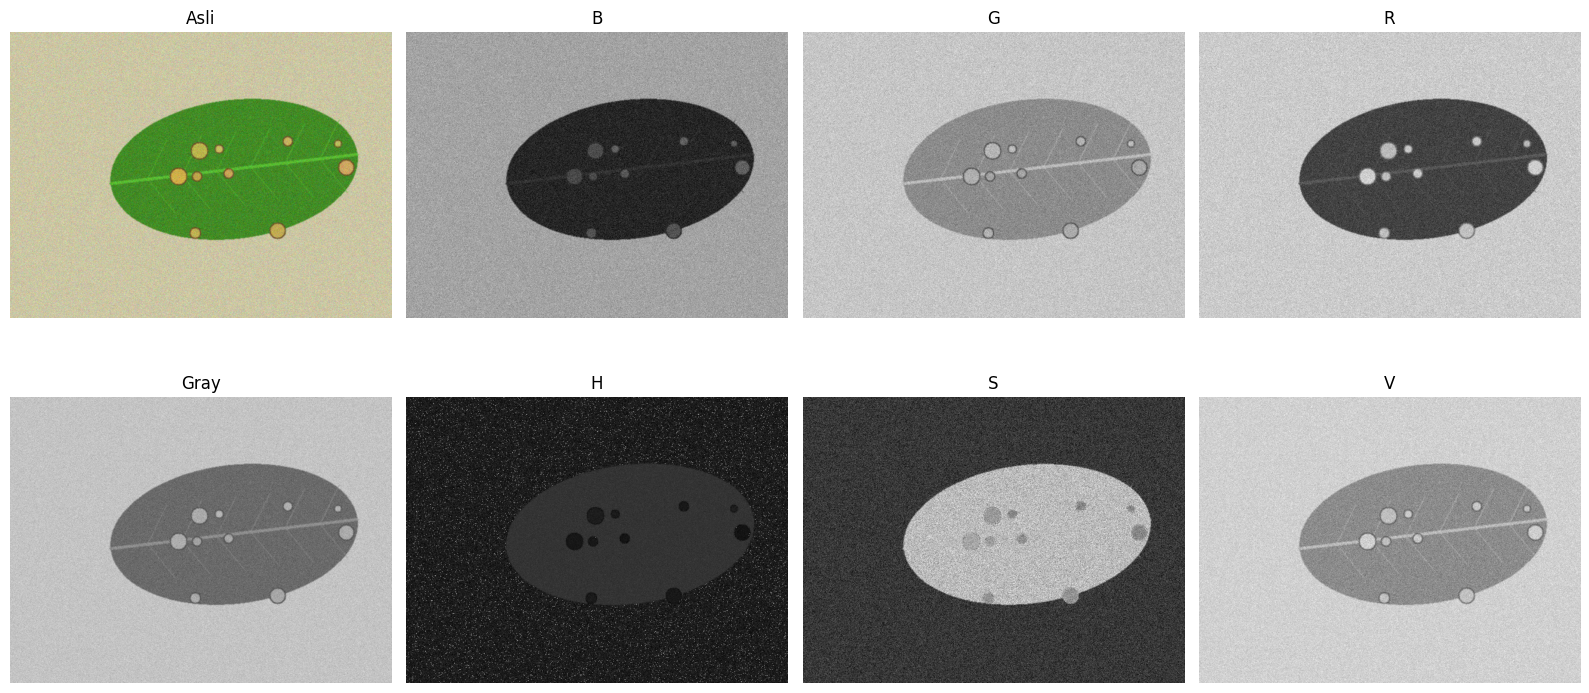

KB kanal B   : 2.24
KB kanal G   : 0.40
KB kanal R   : 7.00
KB kanal Gray: 3.44
KB kanal H   : 5.28
KB kanal S   : 1.40
KB kanal V   : 1.90


In [13]:

nama = "teh_041.png"

img = baca(str(CITRA / nama))
md = cv2.imread(str(MASK_DAUN / nama), cv2.IMREAD_GRAYSCALE)
mb = cv2.imread(str(MASK_BERCAK / nama), cv2.IMREAD_GRAYSCALE)

if img is None or md is None or mb is None:
    raise FileNotFoundError(f"Citra atau mask tidak ditemukan untuk {nama}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {
    "B": b, "G": g, "R": r, "Gray": gray,
    "H": h, "S": s, "V": v
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
gambar = [img] + list(kanal.values())
judul = ["Asli"] + list(kanal.keys())

for ax, im, nm in zip(axes.flat, gambar, judul):
    if im.ndim == 3:
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(nm)
    ax.axis("off")

plt.tight_layout()
plt.show()

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")


In [ ]:

hasil_sampling = []

for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(
        gray, None, fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )
    besar = cv2.resize(
        kecil, gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    kb = kontras_bercak(besar, md, mb)

    hasil_sampling.append({
        "faktor_sampling": fx,
        "tinggi": kecil.shape[0],
        "lebar": kecil.shape[1],
        "KB": kb
    })

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(kecil, cmap="gray")
    ax[0].set_title(f"Sampling {fx}")
    ax[1].imshow(besar, cmap="gray")
    ax[1].set_title(f"Diperbesar kembali, KB={kb:.2f}")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

tabel_sampling = pd.DataFrame(hasil_sampling)
display(tabel_sampling)
tabel_sampling.to_csv(
    HASIL / "b2_sampling.csv", index=False
)


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.29,0.54,5.40,1.80,4.98,0.63,1.24
gelap,1.29,1.57,9.40,4.68,4.83,0.76,3.46
kontras_rendah,0.67,0.23,3.66,1.87,1.93,0.24,1.16
normal,2.11,1.36,8.45,4.46,5.94,0.78,2.90
terang,1.61,0.80,6.28,3.40,4.58,0.56,1.78


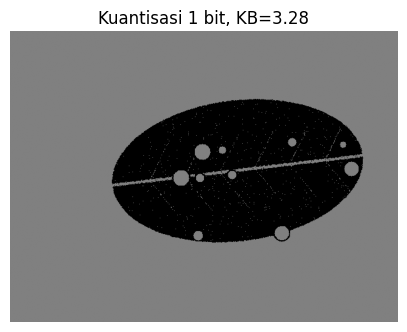

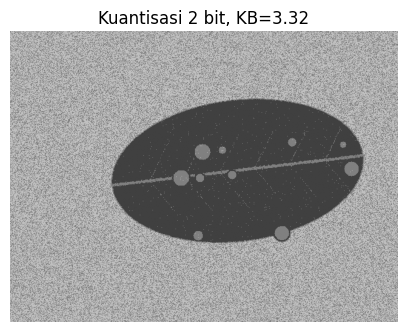

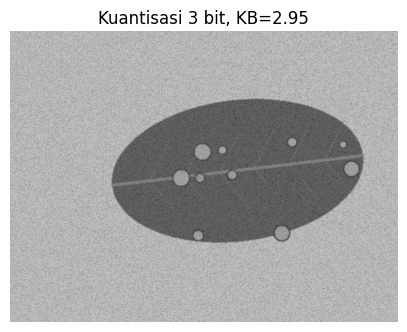

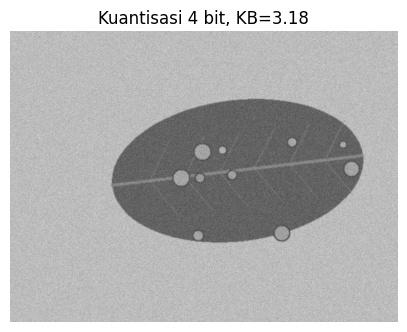

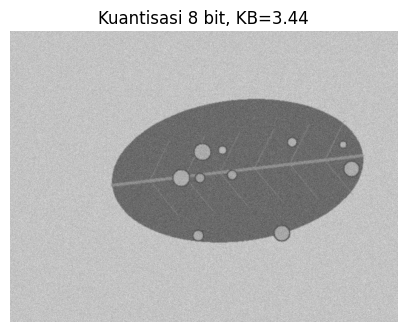

,bit,jumlah_level,KB
0,1,2,3.280757
1,2,3,3.321629
2,3,6,2.945705
3,4,11,3.181540
4,8,170,3.439184


In [18]:

hasil_kuantisasi = []

for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    jumlah_level = len(np.unique(kuant))
    kb = kontras_bercak(kuant, md, mb)

    hasil_kuantisasi.append({
        "bit": k,
        "jumlah_level": jumlah_level,
        "KB": kb
    })

    plt.figure(figsize=(5, 4))
    plt.imshow(kuant, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Kuantisasi {k} bit, KB={kb:.2f}")
    plt.axis("off")
    plt.show()

tabel_kuantisasi = pd.DataFrame(hasil_kuantisasi)
display(tabel_kuantisasi)
tabel_kuantisasi.to_csv(
    HASIL / "b2_kuantisasi.csv", index=False
)


In [19]:

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }

baris = []

for _, d in label[label["kelas"] == "berat"].iterrows():
    nama = d["nama_file"]
    im = baca(str(CITRA / nama))
    m_d = cv2.imread(str(MASK_DAUN / nama), 0)
    m_b = cv2.imread(str(MASK_BERCAK / nama), 0)

    if im is None or m_d is None or m_b is None:
        print("Lewati data tidak lengkap:", nama)
        continue

    nilai = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    nilai["nama_file"] = nama
    nilai["kondisi"] = d["kondisi_cahaya"]
    baris.append(nilai)

df_berat = pd.DataFrame(baris)

tabel_berat = (
    df_berat.groupby("kondisi")[
        ["B", "G", "R", "Gray", "H", "S", "V"]
    ]
    .mean()
    .round(2)
)

display(tabel_berat)
tabel_berat.to_csv(HASIL / "b2_kb_kanal.csv")

df_berat.to_csv(
    HASIL / "b2_kb_kanal_per_citra_berat.csv",
    index=False
)


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.29,0.54,5.40,1.80,4.98,0.63,1.24
gelap,1.29,1.57,9.40,4.68,4.83,0.76,3.46
kontras_rendah,0.67,0.23,3.66,1.87,1.93,0.24,1.16
normal,2.11,1.36,8.45,4.46,5.94,0.78,2.90
terang,1.61,0.80,6.28,3.40,4.58,0.56,1.78


In [20]:

baris_ringan = []

for _, d in label[label["kelas"] == "ringan"].iterrows():
    nama = d["nama_file"]
    im = baca(str(CITRA / nama))
    m_d = cv2.imread(str(MASK_DAUN / nama), 0)
    m_b = cv2.imread(str(MASK_BERCAK / nama), 0)

    if im is None or m_d is None or m_b is None:
        print("Lewati data tidak lengkap:", nama)
        continue

    nilai = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    nilai["nama_file"] = nama
    nilai["kondisi"] = d["kondisi_cahaya"]
    baris_ringan.append(nilai)

df_ringan = pd.DataFrame(baris_ringan)

tabel_ringan = (
    df_ringan.groupby("kondisi")[
        ["B", "G", "R", "Gray", "H", "S", "V"]
    ]
    .mean()
    .round(2)
)

display(tabel_ringan)
tabel_ringan.to_csv(
    HASIL / "b2_kb_kanal_ringan.csv"
)


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,0.84,1.30,4.45,1.26,5.41,0.96,1.00
gelap,0.60,0.42,7.40,2.13,5.48,0.82,1.26
kontras_rendah,0.63,0.48,3.71,1.78,1.98,0.27,1.17
normal,1.27,0.47,7.55,3.29,5.95,0.85,1.63
terang,1.55,0.21,6.06,2.91,4.93,0.94,1.34


Rerata KB kelas berat:


,0
R,6.64
H,4.45
Gray,3.24
V,2.11
B,1.39
G,0.90
S,0.59


Kanal terbaik menurut rerata seluruh citra berat: R


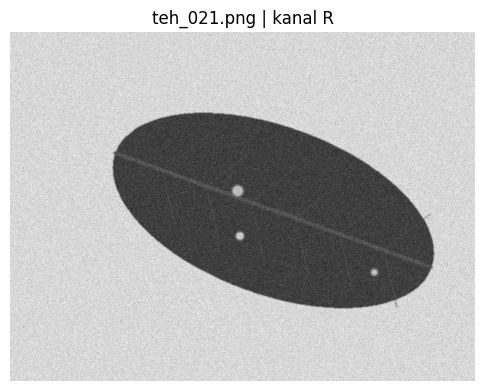

teh_021.png KB kanal terbaik = 7.18


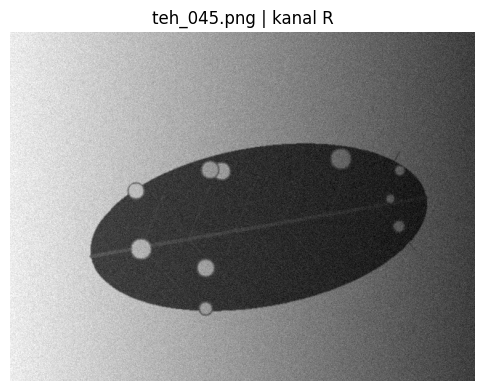

teh_045.png KB kanal terbaik = 5.24


In [21]:

kanal_tersedia = ["B", "G", "R", "Gray", "H", "S", "V"]

rerata_berat_global = df_berat[kanal_tersedia].mean()
kanal_terbaik = rerata_berat_global.idxmax()

print("Rerata KB kelas berat:")
display(rerata_berat_global.sort_values(ascending=False).round(2))
print("Kanal terbaik menurut rerata seluruh citra berat:", kanal_terbaik)

for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(str(CITRA / nama))
    kanal_im = semua_kanal(im)
    pilihan = kanal_im[kanal_terbaik]

    plt.figure(figsize=(6, 5))
    plt.imshow(pilihan, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{nama} | kanal {kanal_terbaik}")
    plt.axis("off")
    plt.show()

    md_i = cv2.imread(str(MASK_DAUN / nama), 0)
    mb_i = cv2.imread(str(MASK_BERCAK / nama), 0)
    print(
        nama,
        "KB kanal terbaik =",
        round(kontras_bercak(pilihan, md_i, mb_i), 2)
    )


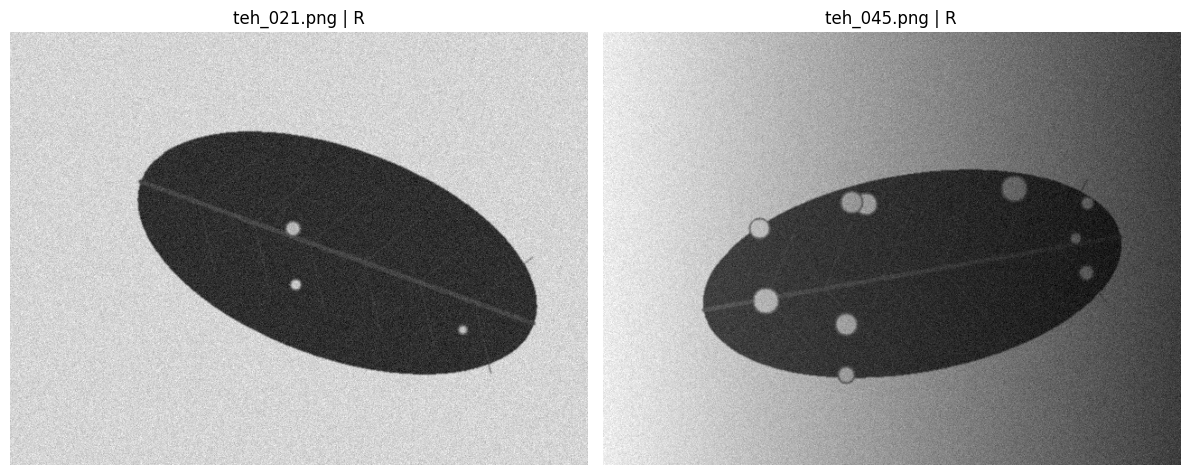

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nama in zip(axes, ["teh_021.png", "teh_045.png"]):
    im = baca(str(CITRA / nama))
    ax.imshow(semua_kanal(im)[kanal_terbaik], cmap="gray")
    ax.set_title(f"{nama} | {kanal_terbaik}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    HASIL / "b2_kanal_terbaik_ringan_berat.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
